# Building Perceptron
## Introduction
Contexte : 
Le Perceptron, inventé par Frank Rosenblatt en 1957, est le premier neurone
artificiel capable d'apprendre à partir d'exemples. C'est le point de départ historique du Deep
Learning.
Objectif : Coder un Perceptron en POO, vérifier qu'il apprend sur des données factices, puis l'utiliser sur un vrai problème médical : prédire si une tumeur du sein est maligne ou bénigne (dataset Breast Cancer Wisconsin).
Plan : 
1. Test du Perceptron sur des données factices
2. Chargement et nettoyage des données
3. Analyse exploratoire
4. Séparation et standardisation
5. Réduction de dimension (ACP)
6. Modélisation avec mon Perceptron
7. Évaluation
8. Conclusion et pistes d'amélioration

### Rappel : comment fonctionne un Perceptron
Le Perceptron reçoit des valeurs d'entrée $x_1, x_2, ..., x_n$ et calcule une somme pondérée :
$$z = w_1 x_1 + w_2 x_2 + ... + w_n x_n + b$$
- $w_i$ : les **poids**, qui donnent l'importance de chaque entrée
- $b$ : le **biais**, qui décale la frontière de décision
- $z$ : le score obtenu
Ensuite il applique la **fonction échelon** (fonction de Heaviside) : il prédit $\hat{y} = 1$ si $z
\geq 0$, sinon $\hat{y} = 0$.
**Règle d'apprentissage.** Après chaque exemple, il corrige ses poids :
$$w_i \leftarrow w_i + \eta \, (y - \hat{y}) \, x_i \qquad \qquad b \leftarrow b + \eta \, (y -
\hat{y})$$
où $\eta$ est le learning rate (taux d'apprentissage). Si la prédiction est juste, $y - \hat{y} = 0$
et les poids ne bougent pas.
Ma classe `Perceptron` est dans le fichier `perceptron.py`. Elle contient :
- `fit(X, y)` : entraîne le modèle en parcourant les données `n_iter` fois (une époque = un passage
complet). Le nombre d'erreurs de chaque époque est gardé dans `errors_`.
- `net_input(X)` : calcule le score $z$.
- `predict(X)` : applique la fonction échelon et renvoie 0 ou 1.

### Imports
J'importe les bibliothèques utiles et ma propre classe Perceptron, écrite dans le fichier
perceptron.py.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from perceptron import Perceptron

## 1. Test du Perceptron sur des données factices
Avant d'utiliser mon Perceptron sur des données médicales, je vérifie qu'il apprend vraiment, sur
un cas où je connais la bonne réponse. Je crée deux nuages de 50 points, bien éloignés l'un de
l'autre.


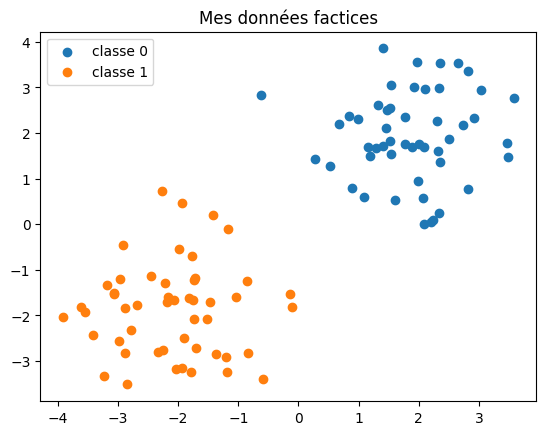

In [33]:
np.random.seed(42)
groupe0 = np.random.randn(50, 2) + [2, 2]
groupe1 = np.random.randn(50, 2) + [-2, -2]
X_facile = np.vstack([groupe0, groupe1])
y_facile = np.array([0] * 50 + [1] * 50)
plt.scatter(X_facile[y_facile == 0, 0], X_facile[y_facile == 0, 1], label="classe 0")
plt.scatter(X_facile[y_facile == 1, 0], X_facile[y_facile == 1, 1], label="classe 1")
plt.legend()
plt.title("Mes données factices")
plt.show()


**Interprétation :** les deux groupes sont bien séparés. Une droite peut les séparer
parfaitement, donc le Perceptron doit réussir à 100 %.

### Entraînement
J'entraîne mon Perceptron avec un learning rate de 0,1 et 20 époques maximum, puis je calcule la
précision.

In [34]:
p = Perceptron(learning_rate=0.1, n_iter=20)
p.fit(X_facile, y_facile)
predictions = p.predict(X_facile)
precision = (predictions == y_facile).mean()
print("Précision :", precision * 100, "%")
print("Erreurs par époque :", p.errors_)

Précision : 100.0 %
Erreurs par époque : [1, 0]


**Interprétation :** la précision est de 100 %. Le Perceptron classe correctement tous les
points. Il fait une seul erreur pendant la première époque, puis pplus aucune 

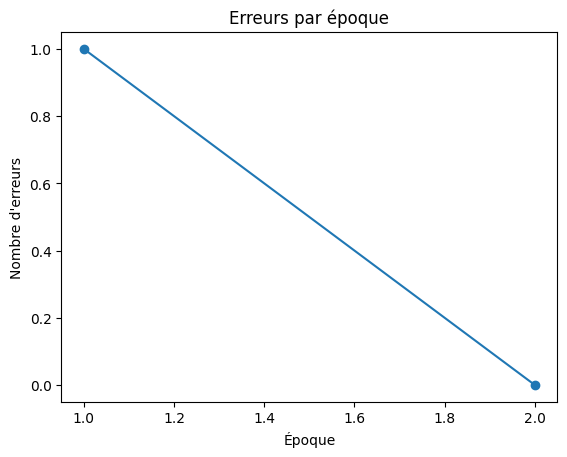

In [35]:
plt.plot(range(1, len(p.errors_) + 1), p.errors_, marker="o")
plt.xlabel("Époque")
plt.ylabel("Nombre d'erreurs")
plt.title("Erreurs par époque")
plt.show()


**Interprétation :** le nombre d'erreurs tombe à 0 très vite. L'apprentissage s'arrête tout seul
dès qu'une époque se termine sans erreur. Cela confirme le théorème de convergence de Novikoff :
si les données sont séparables, le Perceptron trouve une solution en un nombre fini d'étapes.


### Frontière de décision
La frontière correspond à l'équation w1·x1 + w2·x2 + b = 0. J'isole x2 pour tracer la droite : x2
= −(w1·x1 + b) / w2.

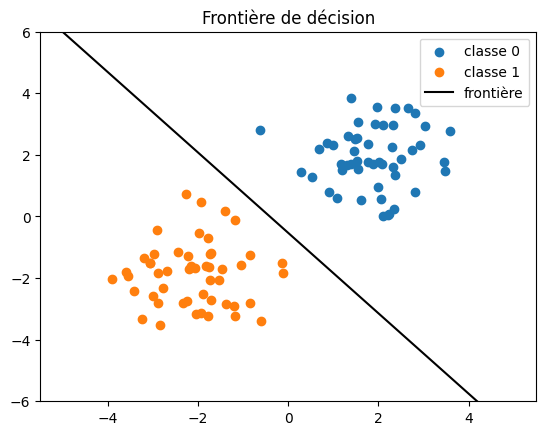

In [36]:
w1 = p.weights_[0]
w2 = p.weights_[1]
b = p.bias_
x1 = np.linspace(-5, 5, 100)
x2 = -(w1 * x1 + b) / w2
plt.scatter(X_facile[y_facile == 0, 0], X_facile[y_facile == 0, 1], label="classe 0")
plt.scatter(X_facile[y_facile == 1, 0], X_facile[y_facile == 1, 1], label="classe 1")
plt.plot(x1, x2, color="black", label="frontière")
plt.ylim(-6, 6)
plt.legend()
plt.title("Frontière de décision")
plt.show()

**Interprétation :** La droite noire coupe le plan en deux. d'un coté le perceptron prédit 0, de l'autre il prédirt 1. C'est ce qu'on appelle un classifieur linéaire.

### Influence du learning rate 
Le learning rate ($\eta$) règle la taille des corrections des poids. Je compare trois valeurs très différentes.

learning rate 0.0001 -> erreurs : [21, 3, 3, 0]
learning rate 0.01 -> erreurs : [1, 0]
learning rate 1 -> erreurs : [1, 0]


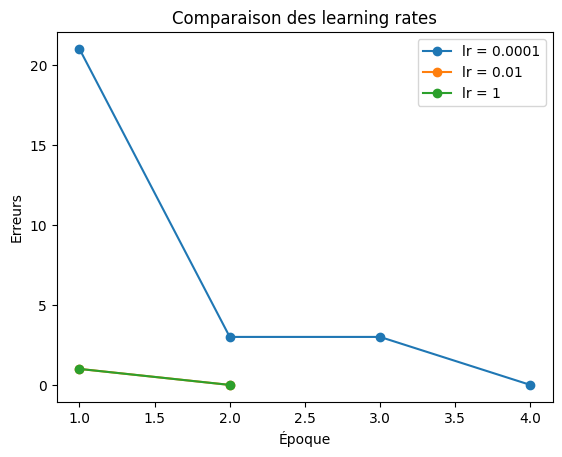

In [37]:
for lr in [0.0001, 0.01, 1]:
    p_test = Perceptron(learning_rate=lr, n_iter=20)
    p_test.fit(X_facile, y_facile)
    print("learning rate", lr, "-> erreurs :", p_test.errors_)
    plt.plot(range(1, len(p_test.errors_) + 1), p_test.errors_, marker="o", label="lr = " +
str(lr))
plt.legend()
plt.xlabel("Époque")
plt.ylabel("Erreurs")
plt.title("Comparaison des learning rates")
plt.show()

**Interprétation :** avec un learning rate très petit (0,0001), il faut plus d'époques pour atteindre
0 erreur, car les corrections sont minuscules par rapport aux poids de départ. Ici les données sont
faciles, donc les trois valeurs finissent par réussir. Sur des données plus difficiles, un learning
rate trop grand peut faire osciller les poids.

### Limite du Perceptron : le XOR
Le XOR (« ou exclusif ») vaut 1 quand les deux entrées sont différentes et 0 quand elles sont
identiques. Aucune droite ne peut séparer ces 4 points.

Erreurs XOR : [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


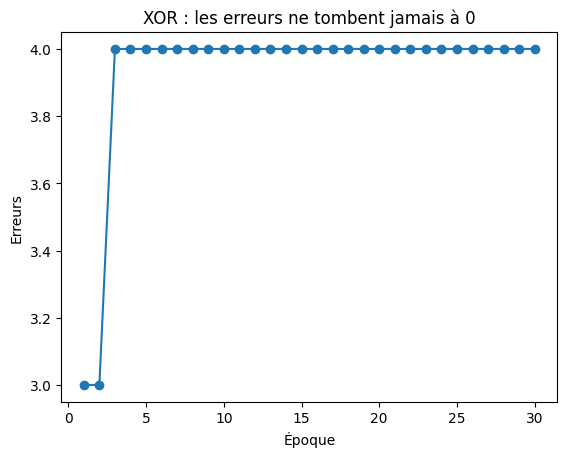

In [38]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])
p_xor = Perceptron(learning_rate=0.1, n_iter=30)
p_xor.fit(X_xor, y_xor)
print("Erreurs XOR :", p_xor.errors_)
plt.plot(range(1, len(p_xor.errors_) + 1), p_xor.errors_, marker="o")
plt.xlabel("Époque")
plt.ylabel("Erreurs")
plt.title("XOR : les erreurs ne tombent jamais à 0")
plt.show()

**Interprétation :** les erreurs ne descendent jamais à 0, même après 30 époques. Le Perceptron ne
peut tracer qu'une droite, et le XOR n'est pas séparable par une droite. C'est la limite démontrée
par Minsky et Papert en 1969. La solution est d'ajouter une couche cachée : c'est le perceptron
multicouche (MLP).

## 2. Chargement et nettoyage des données
Le dataset Breast Cancer Wisconsin (Diagnostic) vient de l'Université du Wisconsin (W. Wolberg, N.
Street et O. Mangasarian, 1995). Chaque ligne décrit une patiente, à partir de l'image numérisée d'un
prélèvement de cellules à l'aiguille fine. On a 30 mesures sur les noyaux des cellules et un
diagnostic : M = malin, B = bénin.
Les 30 mesures viennent de 10 caractéristiques (rayon, texture, périmètre, aire, lissage, compacité,
concavité, points concaves, symétrie, dimension fractale), chacune calculée de 3 façons : la moyenne
(`_mean`), l'erreur standard (`_se`) et la pire valeur (`_worst`).

In [39]:
df = pd.read_csv("bcw_data.csv")
print(df.shape)
df.head()

(569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

**Observation :** le fichier contient 569 lignes et 33 colonnes. Toutes les mesures sont des nombres
(`float64`). La colonne `diagnosis` est du texte (M ou B). La colonne `id` est un numéro de patiente
et la colonne `Unnamed: 32` est complètement vide (0 valeur non nulle).

In [41]:
df = df.drop(columns=["id", "Unnamed: 32"])
print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum())
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})
print(df["diagnosis"].value_counts())
print(df.shape)

Valeurs manquantes : 0
Doublons : 0
diagnosis
0    357
1    212
Name: count, dtype: int64
(569, 31)


**Ce que j'ai fait et pourquoi :**
- J'ai supprimé id car un numéro de patiente n'aide pas à prédire le diagnostic.
- J'ai supprimé Unnamed: 32, car elle est vide.
- Il n'y a aucune valeur manquante et aucun doublon, donc rien d'autre à corriger.
- J'ai encodé la cible : malin = 1 et bénin = 0, car la classe maligne est celle qu'on cherche à
détecter.
Il reste 569 lignes et 31 colonnes : 30 variables et la cible.

## 3. Analyse exploratoire
### Répartition de la cible

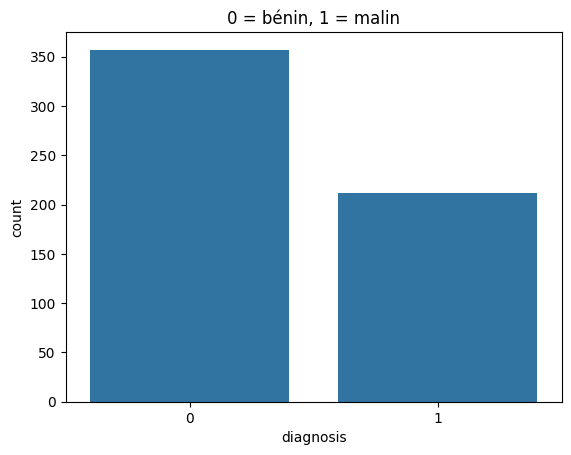

diagnosis
0    62.741652
1    37.258348
Name: proportion, dtype: float64


In [42]:
sns.countplot(x="diagnosis", data=df)
plt.title("0 = bénin, 1 = malin")
plt.show()
print(df["diagnosis"].value_counts(normalize=True) * 100)

**Interprétation :** il y a 357 tumeurs bénignes (62,7 %) et 212 malignes (37,3 %). C'est un léger
déséquilibre. Un modèle qui répondrait toujours « bénin » aurait déjà 63 % d'accuracy sans détecter
un seul cancer. Je ne regarderai donc pas seulement l'accuracy, mais surtout le recall de la classe
maligne.

### Statistiques descriptive

In [43]:
df.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
diagnosis,0.372583,0.483918,0.000000,1.00000
radius_mean,14.127292,3.524049,6.981000,28.11000
texture_mean,19.289649,4.301036,9.710000,39.28000
perimeter_mean,91.969033,24.298981,43.790000,188.50000
area_mean,654.889104,351.914129,143.500000,2501.00000
smoothness_mean,0.096360,0.014064,0.052630,0.16340
compactness_mean,0.104341,0.052813,0.019380,0.34540
concavity_mean,0.088799,0.079720,0.000000,0.42680
concave points_mean,0.048919,0.038803,0.000000,0.20120
symmetry_mean,0.181162,0.027414,0.106000,0.30400


**Interprétation :** les échelles sont très différentes. `area_mean` vaut en moyenne environ 655,
alors que `smoothness_mean` vaut environ 0,1. Sans standardisation, les grandes variables
écraseraient les petites dans le calcul $w \cdot x + b$.

### Distribution des variables selon le diagnostic 
Je regarde les 10 variables _mean, séparement pour les tumeurs bénignes (0) et malignes (1)

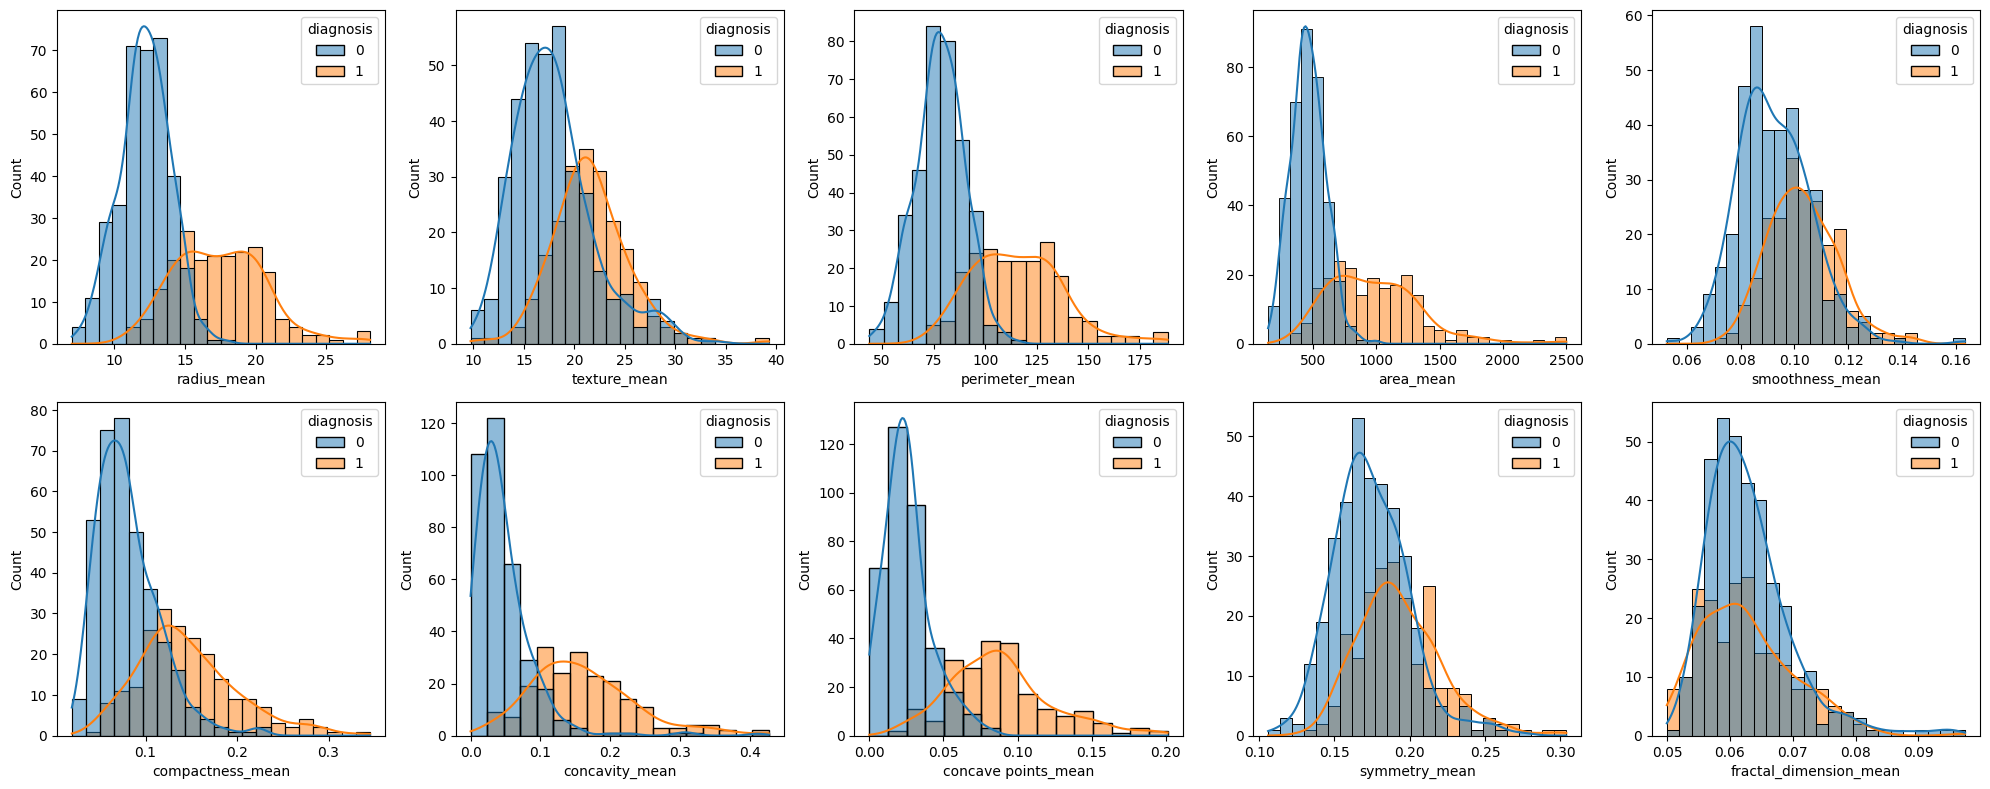

In [44]:
colonnes_mean = []
for col in df.columns:
    if col.endswith("_mean"):
        colonnes_mean.append(col)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()
for i in range(len(colonnes_mean)):
    sns.histplot(data=df, x=colonnes_mean[i], hue="diagnosis", kde=True, ax=axes[i])
plt.tight_layout()
plt.show()

**Interprétation :** `radius_mean`, `perimeter_mean`, `area_mean`, `concavity_mean` et `concave
points_mean` séparent bien les deux classes : les tumeurs malignes ont des noyaux plus gros, plus
irréguliers et plus creusés. À l'inverse, `fractal_dimension_mean` et `symmetry_mean` se chevauchent
beaucoup et sont moins utiles.

### Valeurs extrême 

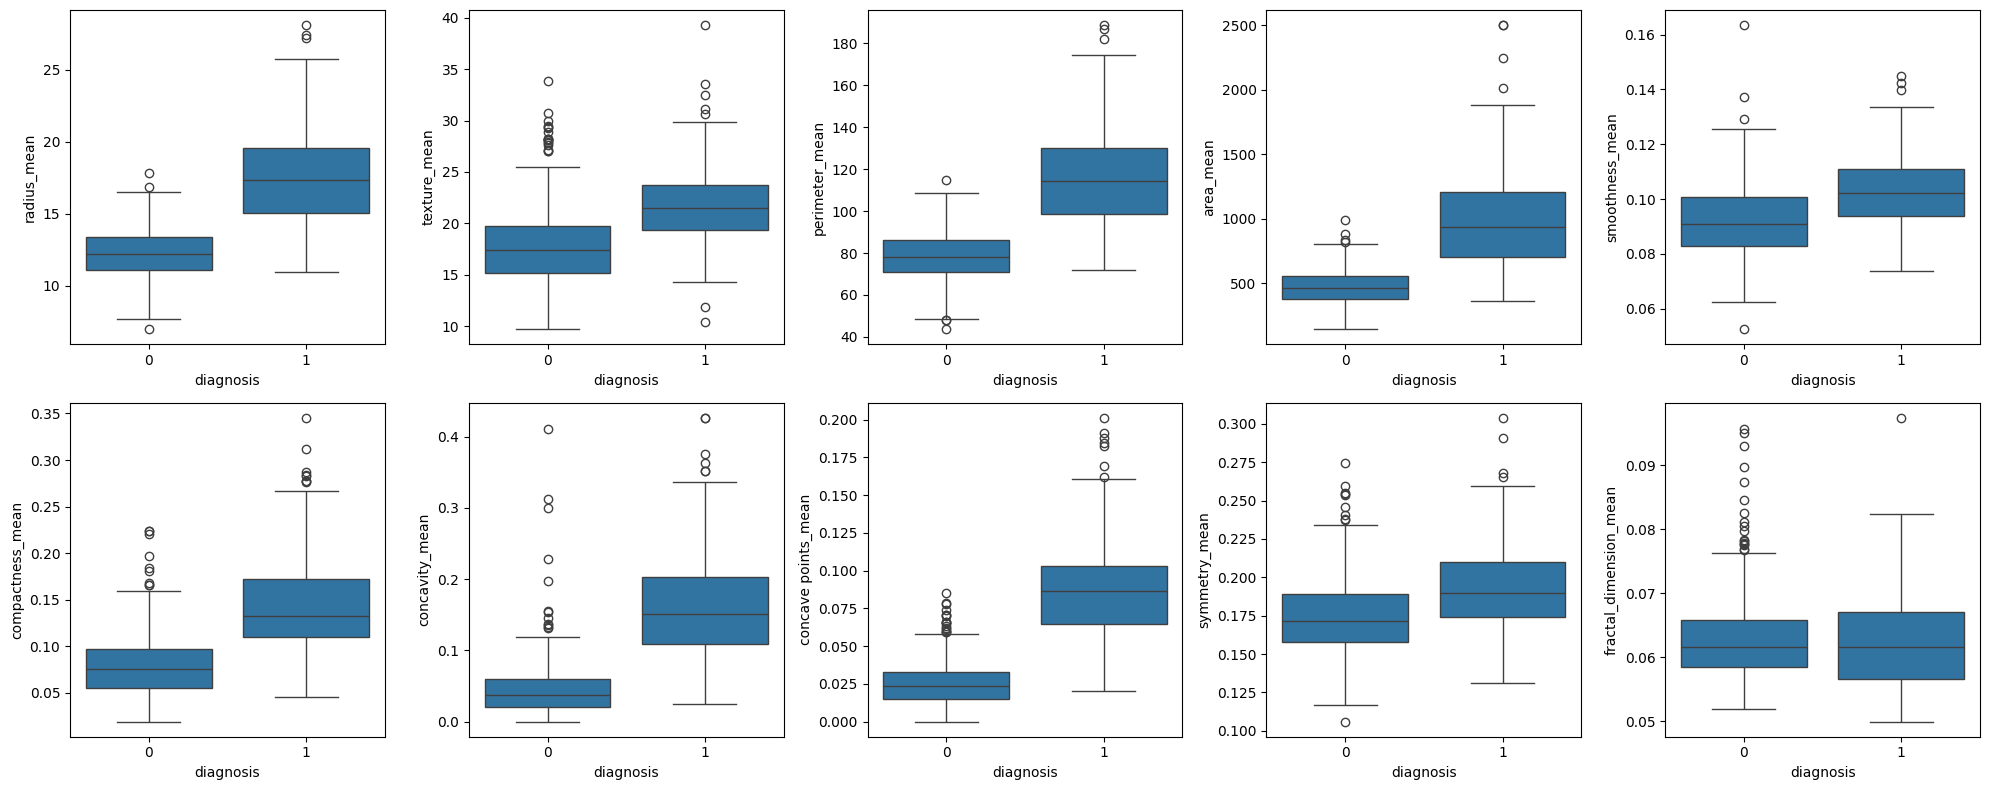

In [45]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()
for i in range(len(colonnes_mean)):
    sns.boxplot(data=df, x="diagnosis", y=colonnes_mean[i], ax=axes[i])
plt.tight_layout()
plt.show()

**Interprétation et décision :** plusieurs variables ont des valeurs extrêmes, surtout du côté malin.
Je les garde, car en médecine une valeur extrême correspond souvent à une vraie grosse tumeur, pas à
une erreur de mesure. Les supprimer ferait perdre justement des cas importants.

### Corrélations entres les variables 

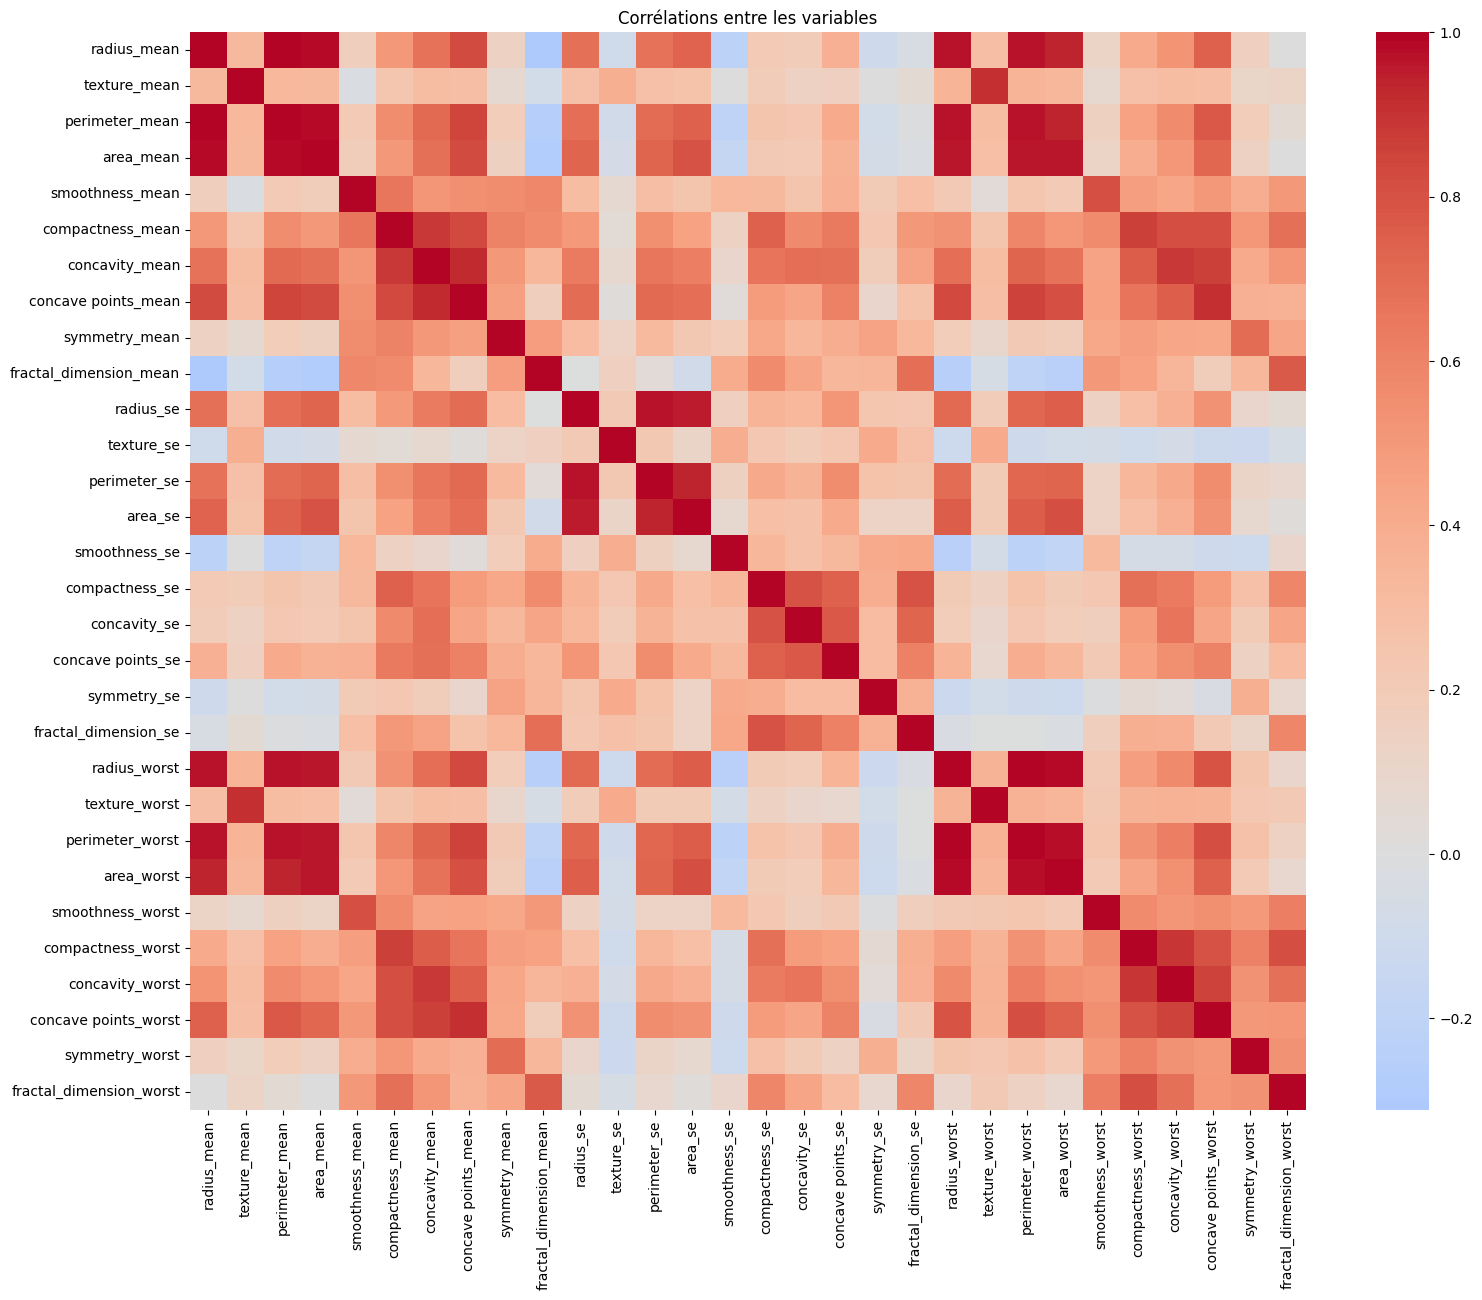

radius_mean <-> perimeter_mean : 1.0
radius_mean <-> area_mean : 0.99
radius_mean <-> radius_worst : 0.97
radius_mean <-> perimeter_worst : 0.97
radius_mean <-> area_worst : 0.94
texture_mean <-> texture_worst : 0.91
perimeter_mean <-> area_mean : 0.99
perimeter_mean <-> radius_worst : 0.97
perimeter_mean <-> perimeter_worst : 0.97
perimeter_mean <-> area_worst : 0.94
area_mean <-> radius_worst : 0.96
area_mean <-> perimeter_worst : 0.96
area_mean <-> area_worst : 0.96
concavity_mean <-> concave points_mean : 0.92
concave points_mean <-> concave points_worst : 0.91
radius_se <-> perimeter_se : 0.97
radius_se <-> area_se : 0.95
perimeter_se <-> area_se : 0.94
radius_worst <-> perimeter_worst : 0.99
radius_worst <-> area_worst : 0.98
perimeter_worst <-> area_worst : 0.98
Nombre de paires au-dessus de 0.9 : 21


In [46]:
correlations = df.drop(columns=["diagnosis"]).corr()
plt.figure(figsize=(18, 14))
sns.heatmap(correlations, cmap="coolwarm", center=0)
plt.title("Corrélations entre les variables")
plt.show()

colonnes = correlations.columns
nb_paires = 0
for i in range(len(colonnes)):
    for j in range(i + 1, len(colonnes)):
        if correlations.iloc[i, j] > 0.9:
            print(colonnes[i], "<->", colonnes[j], ":", round(correlations.iloc[i, j], 2))
            nb_paires = nb_paires + 1
print("Nombre de paires au-dessus de 0.9 :", nb_paires)

**Interprétation :** 21 paires de variables ont une corrélation supérieure à 0,9. Par exemple,
`radius_mean` et `perimeter_mean` sont corrélées à 1,0, ce qui est logique : le périmètre se calcule
à partir du rayon. Beaucoup de variables apportent donc la même information. Cela justifie une
réduction de dimension.

### Nuage de point croisé 
Je croise 4 variables pour voir comment les deux classes se placent les unes par rapport aux autres.

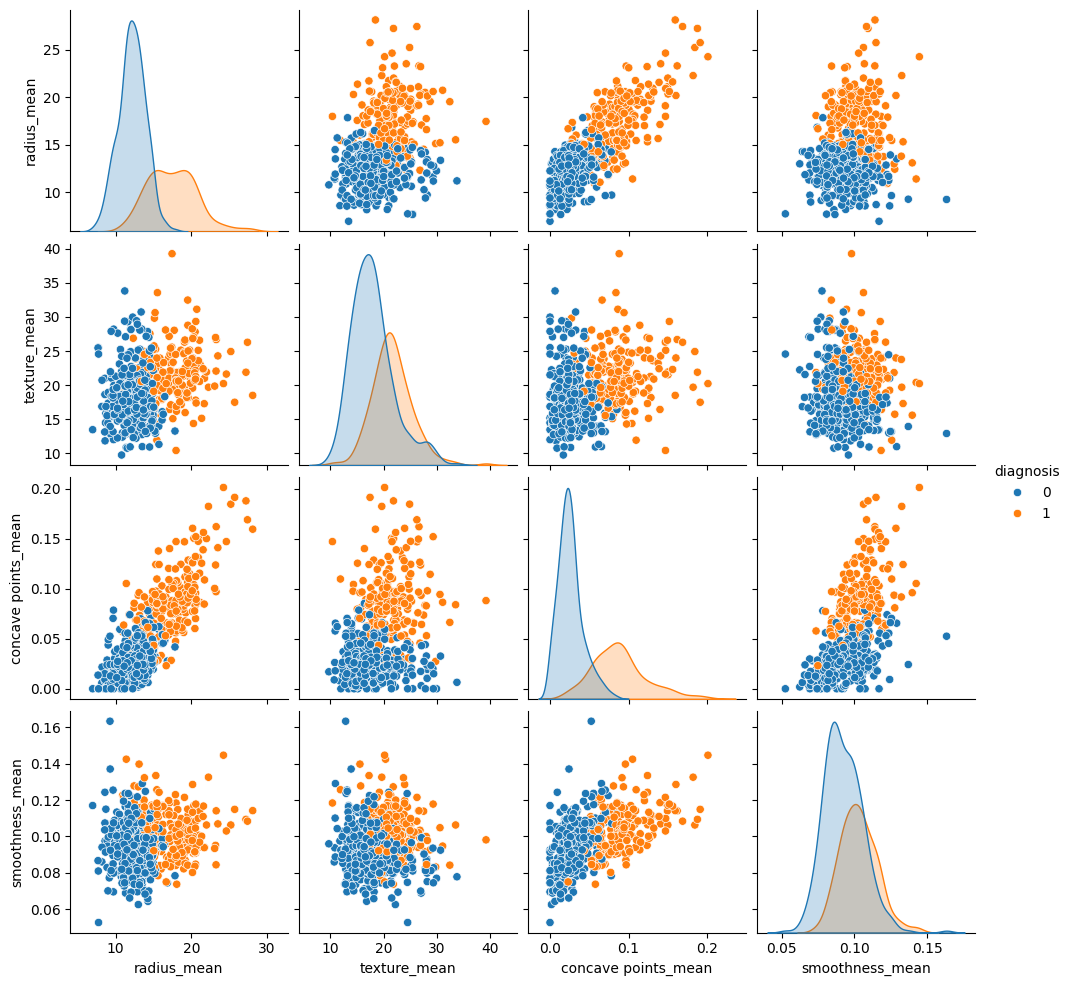

In [47]:
sns.pairplot(df[["radius_mean", "texture_mean", "concave points_mean", "smoothness_mean",
"diagnosis"]], hue="diagnosis")
plt.show()

**Interprétation :** sur les croisements avec `radius_mean` et `concave points_mean`, les deux
couleurs forment deux groupes presque séparés, avec une petite zone de chevauchement. Les données
sont donc presque linéairement séparables, ce qui est favorable au Perceptron.
### Synthèse de l'analyse exploratoire
1. 569 patientes, 30 variables numériques, aucune valeur manquante.
2. Léger déséquilibre : 63 % bénin, 37 % malin.
3. Échelles très différentes : la standardisation est obligatoire.
4. Variables très corrélées entre elles : une réduction de dimension est utile.
5. La taille et la concavité des noyaux séparent bien les classes : les données sont presque
linéairement séparables.

## 4. Séparation et standardisation
Je garde 20 % des données pour le test. Le modèle ne les verra jamais pendant l'entraînement.
L'option `stratify=y` garde la même proportion de malins et de bénins dans les deux parties.
La standardisation met chaque variable à une moyenne de 0 et un écart-type de 1. Le scaler apprend
uniquement sur le train, puis il est appliqué au test. Sinon, des informations du test fuiraient dans
l'entraînement (fuite de données) et les scores seraient trop optimistes.

In [48]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y,
random_state=42)
print(X_train.shape, X_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

(455, 30) (114, 30)


**Résultats :** 455 patientes pourl'entrainement et 144 pour le test 

## 5. Réduction de dimension : l'ACP
**Pourquoi l'ACP ?** Les variables sont très corrélées entre elles. L'ACP (Analyse en Composantes
Principales) crée de nouvelles variables, les composantes, qui résument les anciennes sans
redondance. Elle permet aussi de visualiser les données en 2D. Elle est ajustée sur le train
seulement, comme le scaler.
*Autre méthode possible : Boruta, qui garde les variables les plus utiles au lieu d'en créer de
nouvelles. J'ai choisi l'ACP parce que le problème principal ici est la redondance entre variables.*
Pour choisir le nombre de composantes, je trace la variance expliquée cumulée.

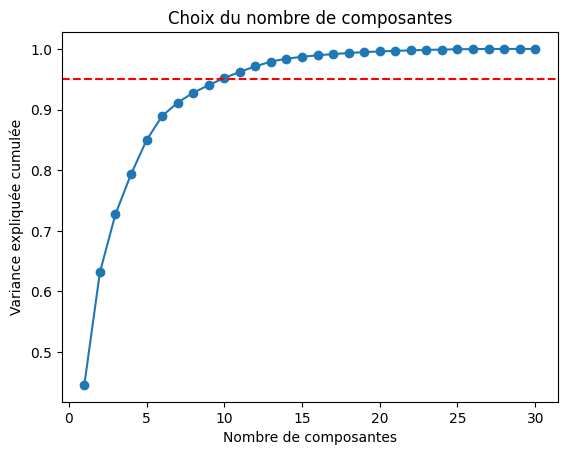

1 composantes : 44.6 %
2 composantes : 63.1 %
3 composantes : 72.7 %
4 composantes : 79.3 %
5 composantes : 84.9 %
6 composantes : 88.9 %
7 composantes : 91.1 %
8 composantes : 92.8 %
9 composantes : 94.0 %
10 composantes : 95.2 %
11 composantes : 96.2 %
12 composantes : 97.1 %


In [49]:
from sklearn.decomposition import PCA 

pca_complete = PCA()
pca_complete.fit(X_train_scaled)
variance_cumulee = np.cumsum(pca_complete.explained_variance_ratio_)
plt.plot(range(1, 31), variance_cumulee, marker="o")
plt.axhline(0.95, color="red", linestyle="--")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.title("Choix du nombre de composantes")
plt.show()
for k in range(12):
    print(k + 1, "composantes :", round(variance_cumulee[k] * 100, 1), "%")

**Interprétation :** la première composante explique déjà 44,6 % de l'information, et les deux
premières 63,1 %. Il faut 10 composantes pour dépasser 95 % (95,2 %). Je passe donc de 30 variables à
10 composantes en gardant presque toute l'information.

In [ ]:
k = 10
pca = PCA(n_components=k)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print(X_train_pca.shape, X_test_pca.shape)
plt.scatter(X_train_pca[y_train == 0, 0], X_train_pca[y_train == 0, 1], label="bénin",
alpha=0.6)
plt.scatter(X_train_pca[y_train == 1, 0], X_train_pca[y_train == 1, 1], label="malin",
alpha=0.6)
plt.xlabel("Composante 1")
plt.ylabel("Composante 2")
plt.title("Les patientes projetées sur les 2 premières composantes")
plt.legend()
plt.show()

**Interprétation :** avec seulement les deux premières composantes, les tumeurs bénignes et malignes
forment deux groupes presque séparés par une droite. C'est pour cette raison que le Perceptron
devrait bien fonctionner ici.

## 6. Modélisation avec mon Perceptron
J'entraîne ma classe sur les 10 composantes de l'ACP, avec un learning rate de 0,01 et 50 époques.

Erreurs par époque : [29, 16, 18, 19, 23, 15, 20, 20, 15, 15, 19, 19, 14, 19, 16, 20, 17, 21, 18, 12, 18, 16, 14, 21, 17, 16, 23, 16, 17, 18, 21, 16, 20, 16, 17, 16, 22, 15, 13, 20, 16, 19, 17, 16, 14, 15, 19, 16, 19, 14]


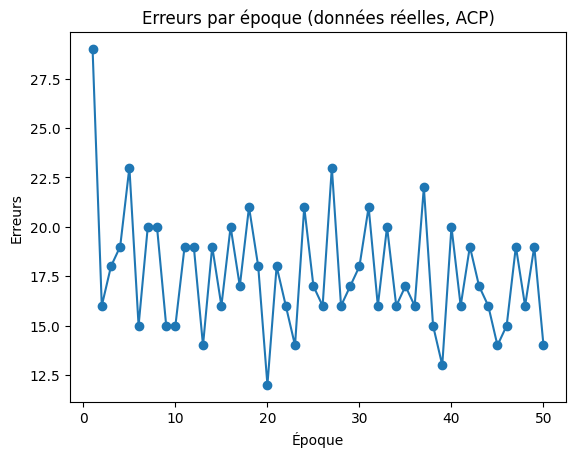

In [51]:
y_train = np.array(y_train)
y_test = np.array(y_test)
mon_perceptron = Perceptron(learning_rate=0.01, n_iter=50)
mon_perceptron.fit(X_train_pca, y_train)
print("Erreurs par époque :", mon_perceptron.errors_)
plt.plot(range(1, len(mon_perceptron.errors_) + 1), mon_perceptron.errors_, marker="o")
plt.xlabel("Époque")
plt.ylabel("Erreurs")
plt.title("Erreurs par époque (données réelles, ACP)")
plt.show()

**Interprétation :** contrairement aux données factices, la courbe ne descend jamais à 0. Après une
première époque à 29 erreurs, elle oscille entre 12 et 23 erreurs par époque, sur 455 patientes. Les
données réelles ne sont pas parfaitement séparables : quelques patientes se trouvent du mauvais côté
de toute droite possible. Le Perceptron continue donc de corriger ses poids sans jamais s'arrêter
seul, comme pour le XOR mais en beaucoup moins grave.



### Réglage des hyperparamètres par validation croisée
Pour choisir le learning rate et le nombre d'époques sans tricher, je n'utilise que le train. Je le
découpe en 5 parties : j'entraîne sur 4 parties et je teste sur la 5e, cinq fois de suite, puis je
fais la moyenne des scores.

In [52]:
from sklearn.model_selection import StratifiedKFold

plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for lr in [0.001, 0.01, 0.1, 1]:
    for n in [10, 50, 100]:
        scores = []
        for index_train, index_val in plis.split(X_train_pca, y_train):
            p_cv = Perceptron(learning_rate=lr, n_iter=n)
            p_cv.fit(X_train_pca[index_train], y_train[index_train])
            pred_val = p_cv.predict(X_train_pca[index_val])
            scores.append((pred_val == y_train[index_val]).mean())
        print("lr =", lr, "n_iter =", n, "-> score moyen :", round(np.mean(scores) * 100,
1), "%")

lr = 0.001 n_iter = 10 -> score moyen : 95.4 %
lr = 0.001 n_iter = 50 -> score moyen : 96.7 %
lr = 0.001 n_iter = 100 -> score moyen : 96.0 %
lr = 0.01 n_iter = 10 -> score moyen : 96.7 %
lr = 0.01 n_iter = 50 -> score moyen : 95.8 %
lr = 0.01 n_iter = 100 -> score moyen : 96.0 %
lr = 0.1 n_iter = 10 -> score moyen : 96.0 %
lr = 0.1 n_iter = 50 -> score moyen : 96.0 %
lr = 0.1 n_iter = 100 -> score moyen : 96.9 %
lr = 1 n_iter = 10 -> score moyen : 96.3 %
lr = 1 n_iter = 50 -> score moyen : 95.6 %
lr = 1 n_iter = 100 -> score moyen : 95.4 %


**Interprétation :** tous les réglages donnent un score moyen entre 95,4 % et 96,9 %. L'écart entre
le meilleur et le moins bon est de 1,5 point seulement, ce qui correspond à 1 ou 2 patientes par
pli : le modèle est stable et le choix des hyperparamètres compte peu ici. Je garde donc le réglage
simple du début (lr = 0,01 et 50 époques).

## 7. Évaluation sur le jeu de test
Dans un diagnostic médical, l'erreur la plus grave est le **faux négatif** : dire « bénin » à une
patiente qui a un cancer. Je regarde donc la matrice de confusion et le **recall** de la classe
maligne en priorité.
Rappel des métriques :
- **Accuracy** : part des patientes bien classées.
- **Recall (sensibilité)** : parmi les vrais cancers, combien sont détectés.
- **Précision** : quand le modèle dit « malin », combien de fois il a raison.
- **Spécificité** : parmi les tumeurs bénignes, combien sont bien reconnues.
- **F1-score** : moyenne entre précision et recall.

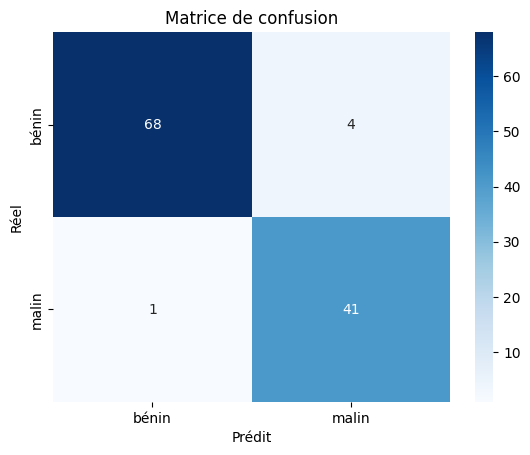

              precision    recall  f1-score   support

       bénin       0.99      0.94      0.96        72
       malin       0.91      0.98      0.94        42

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114

Faux négatifs (cancers ratés) : 1
Spécificité : 94.4 %


In [53]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, recall_score

y_pred = mon_perceptron.predict(X_test_pca)
matrice = confusion_matrix(y_test, y_pred)

sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", xticklabels=["bénin", "malin"],
yticklabels=["bénin", "malin"])
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion")
plt.show()

print(classification_report(y_test, y_pred, target_names=["bénin", "malin"]))
vn = matrice[0, 0]
fp = matrice[0, 1]
fn = matrice[1, 0]
vp = matrice[1, 1]
print("Faux négatifs (cancers ratés) :", fn)
print("Spécificité :", round(vn / (vn + fp) * 100, 1), "%")

**Interprétation :**
- **Accuracy : 95,6 %** des patientes du test sont bien classées (109 sur 114).
- **Recall malin : 97,6 %**, soit 41 cancers détectés sur 42. Un seul cancer est raté (faux négatif).
- **Précision malin : 91 %.** Quand le modèle dit « malin », il a raison 9 fois sur 10. Les autres
cas sont des fausses alertes (4 faux positifs) : elles entraînent des examens en plus, mais pas de
cancer oublié.
- **Spécificité : 94,4 %** des tumeurs bénignes sont bien reconnues.
Pour un usage médical, il vaut mieux quelques fausses alertes qu'un cancer manqué. Le modèle fait
donc plutôt le bon type d'erreur.

### Courbe ROC et AUC
Le Perceptron ne donne pas de probabilité, mais `net_input` donne un score continu $z = w \cdot x +
b$. Je l'utilise pour tracer la courbe ROC et calculer l'aire sous la courbe (AUC). Une AUC de 1 veut
dire un classement parfait, 0,5 veut dire un tirage au hasard.

ROC-AUC : 0.991


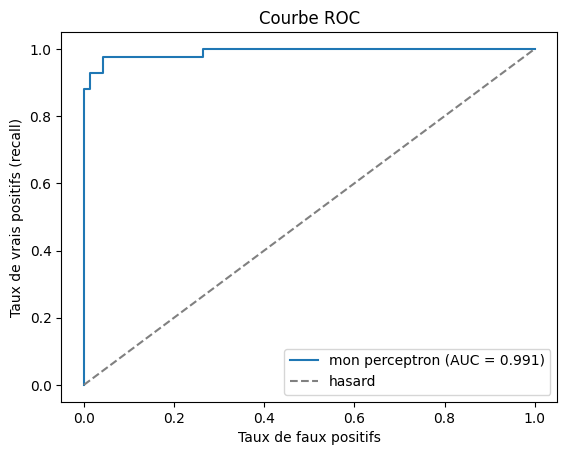

In [54]:
from sklearn.metrics import roc_auc_score, roc_curve
scores_z = mon_perceptron.net_input(X_test_pca)
auc = roc_auc_score(y_test, scores_z)
print("ROC-AUC :", round(auc, 3))
fpr, tpr, seuils = roc_curve(y_test, scores_z)
plt.plot(fpr, tpr, label="mon perceptron (AUC = " + str(round(auc, 3)) + ")")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="hasard")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs (recall)")
plt.title("Courbe ROC")
plt.legend()
plt.show()

**Interprétation :** l'AUC vaut 0,991, très proche de 1. La courbe monte presque tout de suite en
haut à gauche : le score $z$ place presque toujours une tumeur maligne au-dessus d'une tumeur
bénigne.

In [ ]:
p_30 = Perceptron(learning_rate=0.01, n_iter=50)
p_30.fit(X_train_scaled, y_train)
y_pred_30 = p_30.predict(X_test_scaled)

from sklearn.linear_model import Perceptron as PerceptronSklearn
p_sk = PerceptronSklearn(max_iter=50, random_state=42)
p_sk.fit(X_train_pca, y_train)
y_pred_sk = p_sk.predict(X_test_pca)

resultats = pd.DataFrame({
"modèle": ["Mon perceptron + ACP", "Mon perceptron 30 variables", "Perceptron sklearn + ACP"],
    "accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_30),
accuracy_score(y_test, y_pred_sk)],
    "recall malin": [recall_score(y_test, y_pred), recall_score(y_test, y_pred_30),
recall_score(y_test, y_pred_sk)],
})
resultats

**Interprétation :**
- Mon Perceptron obtient un score proche de celui de scikit-learn (95,6 % contre 96,5 % d'accuracy).
Ma classe fonctionne donc correctement.
- Avec l'ACP, le recall passe de 88,1 % à 97,6 %. Sur les 30 variables brutes, le modèle rate 5
cancers au lieu d'un seul. La réduction de dimension aide vraiment le Perceptron, car elle retire la
redondance qui le rend instable.

## 8. Conclusion
**Le Perceptron est-il efficace ici ?** Oui. Avec la standardisation et l'ACP, mon Perceptron atteint
95,6 % d'accuracy et 97,6 % de recall sur des patientes qu'il n'a jamais vues. Il ne rate qu'un
cancer sur 42. Il fonctionne bien parce que les données sont presque linéairement séparables.
**Pourquoi il ne suffit pas pour un usage médical :**
- Il ne donne pas de probabilité : impossible de dire « malin à 80 % ».
- On ne peut pas facilement régler son seuil pour privilégier encore plus le recall.
- Il ne converge pas sur des données non séparables : le résultat dépend du nombre d'époques et de
l'ordre des exemples.
- Il trouve une frontière qui sépare, mais pas forcément la meilleure.
**Pistes d'amélioration (non implémentées) :**
1. **La régression logistique** : elle remplace la fonction échelon par une sigmoïde, donne une
probabilité et permet de régler le seuil de décision.
2. **Le SVM** : il cherche la frontière avec la marge maximale, donc plus robuste.
3. **Le perceptron multicouche (MLP)** : avec une couche cachée, il peut tracer des frontières non
linéaires.
4. **Les forêts aléatoires** : très performantes sur les données en tableau.
5. **La pondération des classes** : donner plus de poids aux tumeurs malignes pendant l'entraînement
pour réduire encore les faux négatifs.
6. **Plus de données et une validation par des médecins** : 569 patientes, c'est peu pour un outil
médical.